# Proyecto de flujo de datos — Bicis compartidas de Toulouse (estación *pomme*)

**Notebook 1: construcción del flujo de datos y análisis exploratorio** (secciones 2 y 3 de la memoria).

**Objetivo del proyecto:** un sistema de alerta que, **cada 30 minutos**, prediga si **dentro de 2 horas** la estación *pomme* tendrá **2 bicis o menos** (tiempo suficiente para avisar a los usuarios o reponer bicis), y que detecte cuándo cambia el patrón de uso (*data drift*) y cuándo el modelo deja de ser fiable (*concept drift*).

**Dataset:** `Bikes` de River (OpenBikes 2016 Challenge): lecturas del número de bicis disponibles en 5 estaciones de Toulouse, con el tiempo meteorológico de la ciudad en cada lectura.
- Documentación: https://riverml.xyz/latest/api/datasets/Bikes/
- Origen de los datos: https://maxhalford.github.io/blog/openbikes-challenge/

> El análisis exploratorio usa todo el histórico **solo para entender los datos y justificar decisiones**. Los modelos de los siguientes notebooks recorren el flujo instancia a instancia y nunca ven el futuro.

## 0. Instalación e imports

**En Google Colab:** instalar River actualiza `numpy` y Colab necesita reiniciar la sesión. La celda siguiente lo hace sola: si se reinicia, **continuad desde la celda de los `import`**. El aviso de `numba` que puede salir no afecta.

In [27]:
import importlib.metadata as metadata
import os
import sys

numpy_antes = metadata.version("numpy")
%pip install -q river
if "google.colab" in sys.modules and metadata.version("numpy") != numpy_antes:
    print("Reiniciando la sesión... después ejecutad desde la celda de los imports")
    os.kill(os.getpid(), 9)
else:
    print("River instalado")

Note: you may need to restart the kernel to use updated packages.
River instalado



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [28]:
import time
from itertools import islice

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import river
from river import datasets, drift, metrics, stream, tree

print("River:", river.__version__)

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

# Estilo de las gráficas
AZUL, NARANJA, GRIS, SOMBRA, TINTA = "#2a78d6", "#eb6834", "#8a8985", "#e6e5e0", "#2b2b2a"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": SOMBRA, "grid.linewidth": 0.6,
    "axes.edgecolor": GRIS, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "font.size": 9.5,
})

River: 0.26.1


# 2. Descripción y construcción del flujo de datos

## 2.1 Descarga y descripción del dataset

River descarga el CSV la primera vez y lo guarda en la carpeta `river_data/Bikes`.

In [29]:
dataset = datasets.Bikes()
dataset.download()
print(dataset)
print("CSV en:", dataset.path)

Bike sharing station information from the city of Toulouse.

The goal is to predict the number of bikes in 5 different bike stations from the city of
Toulouse.

      Name  Bikes                                                         
      Task  Regression                                                    
   Samples  182,470                                                       
  Features  8                                                             
    Sparse  False                                                         
      Path  C:\Users\User\river_data\Bikes\toulouse_bikes.csv             
       URL  https://maxhalford.github.io/files/datasets/toulouse_bikes.zip
      Size  12.52 MiB                                                     
Downloaded  True                                                          
CSV en: C:\Users\User\river_data\Bikes\toulouse_bikes.csv


Para el análisis cargamos el CSV completo con pandas. Cada fila es una **lectura** del estado de una estación:

| Columna | Significado |
|---|---|
| `moment` | fecha y hora de la lectura |
| `station` | estación (5 en total) |
| `bikes` | número de bicis disponibles en ese momento |
| `clouds`, `description`, `humidity`, `pressure`, `temperature`, `wind` | tiempo meteorológico en Toulouse en ese momento (nubosidad %, descripción, humedad %, presión hPa, temperatura °C, viento m/s) |

In [30]:
df = pd.read_csv(dataset.path, parse_dates=["moment"])
print(df.shape)
df.head()

(182470, 9)


,moment,bikes,station,clouds,description,humidity,pressure,temperature,wind
0,2016-04-01 00:00:07,1,metro-canal-du-midi,75,light rain,81,1017.0,6.54,9.3
1,2016-04-01 00:00:16,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
2,2016-04-01 00:00:35,3,place-des-carmes,75,light rain,81,1017.0,6.54,9.3
3,2016-04-01 00:04:50,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3
4,2016-04-01 00:05:29,2,place-esquirol,75,light rain,81,1017.0,6.54,9.3


## 2.2 Calidad del CSV original

Antes de construir el flujo comprobamos: valores ausentes, duplicados, orden temporal, cuántas lecturas tiene cada estación y si hay cortes en la recogida de datos.

In [31]:
print("Valores ausentes por columna:", df.isna().sum().to_dict())
print("Filas duplicadas:", df.duplicated().sum())
print("¿Ordenado por fecha?", df["moment"].is_monotonic_increasing)
print("Periodo:", df["moment"].min(), "->", df["moment"].max())
print()
print("Lecturas por estación y mes:")
pd.crosstab(df["station"], df["moment"].dt.month.rename("mes"), margins=True)

Valores ausentes por columna: {'moment': 0, 'bikes': 0, 'station': 0, 'clouds': 0, 'description': 0, 'humidity': 0, 'pressure': 0, 'temperature': 0, 'wind': 0}
Filas duplicadas: 19
¿Ordenado por fecha? True
Periodo: 2016-04-01 00:00:07 -> 2016-10-05 09:57:18

Lecturas por estación y mes:


mes,4,5,6,7,8,9,10,All
station,,,,,,,,
metro-canal-du-midi,3970,2186,5161,4775,4817,4687,733,26329
place-des-carmes,6851,3404,4945,4913,5004,5310,700,31127
place-esquirol,10550,5322,7730,7799,8354,8294,1187,49236
place-jeanne-darc,4550,2564,4480,4299,4200,4468,685,25246
pomme,7916,4252,9617,9458,8717,9265,1307,50532
All,33837,17728,31933,31244,31092,32024,4612,182470


In [32]:
# Intervalo entre lecturas consecutivas de cada estación (minutos)
df = df.sort_values(["station", "moment"])
df["intervalo_min"] = df.groupby("station")["moment"].diff().dt.total_seconds() / 60
print("Intervalo entre lecturas (minutos):")
print(df.groupby("station")["intervalo_min"].describe(percentiles=[.25, .5, .75, .9]).round(1))

Intervalo entre lecturas (minutos):
                       count  mean    std  min  25%   50%   75%   90%      max
station                                                                       
metro-canal-du-midi  26328.0  10.3   99.6  0.0  5.5  10.0  10.1  10.1  10530.1
place-des-carmes     31126.0   8.7   91.1  0.0  2.2   5.8  10.1  13.7  10531.1
place-esquirol       49235.0   5.5   72.4  0.0  1.6   3.0   6.4  10.1  10528.6
place-jeanne-darc    25245.0  10.7  101.2  0.0  4.3  10.0  10.1  14.8  10530.6
pomme                50531.0   5.3   71.3  0.0  1.7   3.0   7.4  10.1  10527.9


In [33]:
# Cortes en la recogida: huecos de más de 2 horas sin ninguna lectura (de ninguna estación)
todas = df.sort_values("moment")["moment"].reset_index(drop=True)
hueco = todas.diff()
cortes = pd.DataFrame({"desde": todas.shift()[hueco > pd.Timedelta(hours=2)],
                       "hasta": todas[hueco > pd.Timedelta(hours=2)],
                       "duracion": hueco[hueco > pd.Timedelta(hours=2)]}).reset_index(drop=True)
print(f"{len(cortes)} cortes de más de 2 h; tiempo total sin datos: {cortes['duracion'].sum()}")
cortes

13 cortes de más de 2 h; tiempo total sin datos: 29 days 06:00:19


,desde,hasta,duracion
0,2016-04-06 13:14:05,2016-04-10 01:18:13,3 days 12:04:08
1,2016-04-12 22:38:12,2016-04-16 01:57:16,3 days 03:19:04
2,2016-04-21 00:16:18,2016-04-21 02:19:01,0 days 02:02:43
3,2016-04-21 21:07:04,2016-04-24 00:19:43,2 days 03:12:39
4,2016-04-25 23:58:10,2016-04-26 09:24:12,0 days 09:26:02
5,2016-05-04 07:15:57,2016-05-09 22:58:11,5 days 15:42:14
6,2016-05-11 08:52:11,2016-05-13 13:54:05,2 days 05:01:54
7,2016-05-14 17:20:05,2016-05-16 00:34:14,1 days 07:14:09
8,2016-05-18 06:53:42,2016-05-25 14:16:52,7 days 07:23:10
9,2016-05-26 03:36:44,2016-05-28 00:17:51,1 days 20:41:07


**Qué vemos:**
- No hay valores ausentes y solo hay 19 filas duplicadas exactas (se eliminan). El CSV está ordenado por fecha, pero **mezcla las 5 estaciones** en orden de llegada: para tener el flujo de una estación hay que filtrarlo.
- **Las lecturas no llegan a intervalos regulares.** En las estaciones con más movimiento llega una cada 1-4 minutos; en las tranquilas, cada ~10. El recolector original parece guardar una lectura cuando cambia algo y, si no, cada ~10 minutos.
- **Hay cortes en la recogida de datos**, casi todos en **abril y mayo** (de horas a 7 días seguidos) y uno de ~1 día en septiembre. Octubre solo tiene 5 días.

## 2.3 Selección de la estación y del periodo

- **Estación *pomme*:** es la que más lecturas tiene y la que más veces se queda sin bicis (ver tabla siguiente), así que el problema de alerta tiene sentido.
- **Periodo: del 1 de junio al 5 de octubre de 2016.** Abril y mayo tienen tantos cortes que el flujo tendría saltos de varios días; un detector de drift los confundiría con cambios reales.

In [34]:
resumen_est = df.groupby("station").agg(
    lecturas=("bikes", "size"),
    bicis_media=("bikes", "mean"),
    bicis_max=("bikes", "max"),
    pct_lecturas_vacia=("bikes", lambda s: 100 * (s == 0).mean()),
).round(1).sort_values("lecturas", ascending=False)
resumen_est

,lecturas,bicis_media,bicis_max,pct_lecturas_vacia
station,,,,
pomme,50532,8.3,18,11.5
place-esquirol,49236,16.0,34,9.2
place-des-carmes,31127,7.5,20,13.2
metro-canal-du-midi,26329,9.6,25,4.1
place-jeanne-darc,25246,5.7,25,9.2


In [35]:
ESTACION = "pomme"
INICIO = "2016-06-01"

pomme = (df[(df["station"] == ESTACION) & (df["moment"] >= INICIO)]
         .drop(columns=["station", "intervalo_min"]).drop_duplicates()
         .sort_values("moment").reset_index(drop=True))
print(f"Lecturas de {ESTACION} desde {INICIO}: {len(pomme):,}")
print("Periodo:", pomme["moment"].min(), "->", pomme["moment"].max())

Lecturas de pomme desde 2016-06-01: 38,358
Periodo: 2016-06-01 00:07:07 -> 2016-10-05 09:57:18


**¿Reponen las bicis cuando la estación se queda vacía?** Si un camión repusiera bicis a menudo, quedarse sin bicis dependería de la empresa y no de los usuarios. Lo comprobamos mirando cómo sale la estación de cada episodio con 0 bicis: si sube de 1 en 1, las devuelve un usuario; si sube 5 o más de golpe, es una reposición.

In [36]:
def episodios_vacia(lecturas):
    """Episodios con 0 bicis: duración y cuántas bicis aparecen al salir de él."""
    l = lecturas.reset_index(drop=True)
    vacia = l["bikes"].eq(0)
    grupo = (vacia != vacia.shift()).cumsum()
    filas = []
    for _, e in l[vacia].groupby(grupo[vacia]):
        fin = e.index[-1] + 1
        if fin >= len(l):
            continue
        duracion = (l.loc[fin, "moment"] - e["moment"].iloc[0]).total_seconds() / 60
        if duracion > 24 * 60:          # episodios que cruzan un corte de datos
            continue
        filas.append({"inicio": e["moment"].iloc[0], "duracion_min": duracion, "bicis_al_salir": l.loc[fin, "bikes"]})
    return pd.DataFrame(filas)

ep = episodios_vacia(pomme)
print(f"Episodios con la estación vacía: {len(ep)}")
print(f"Duración (min): mediana {ep['duracion_min'].median():.0f} | p75 {ep['duracion_min'].quantile(.75):.0f} | "
      f"p90 {ep['duracion_min'].quantile(.9):.0f} | máx {ep['duracion_min'].max():.0f}")
print("Cómo sale de vacía:")
print(pd.cut(ep["bicis_al_salir"], [0, 1, 4, 100], labels=["+1 bici (usuario)", "+2 a +4", "+5 o más (reposición)"])
      .value_counts(normalize=True).mul(100).round(1).to_string())

Episodios con la estación vacía: 1033
Duración (min): mediana 12 | p75 43 | p90 101 | máx 440
Cómo sale de vacía:
bicis_al_salir
+1 bici (usuario)        79.1
+2 a +4                  20.6
+5 o más (reposición)     0.3


Casi siempre sale de vacía con **una bici que devuelve un usuario**; las reposiciones son excepcionales. Quedarse sin bicis depende del **comportamiento de los usuarios**, que es justo lo que el modelo tiene que aprender (y lo que puede cambiar con el tiempo).

## 2.4 Construcción del flujo regular: una instancia cada 30 minutos

Las lecturas originales llegan a intervalos irregulares (de segundos a 10 minutos). Construimos un flujo **regular**: cada 30 minutos llega una instancia con el **estado de la estación en ese momento** (la última lectura de la media hora). En la sección 2.5 justificamos esta decisión con un experimento.

**Variables de cada instancia** (solo información disponible en el instante *t*):

| Variable | Descripción |
|---|---|
| `momento` | instante *t* (solo para registro; no se usa como variable del modelo) |
| `bicis` | bicis disponibles en *t* |
| `tendencia_1h` | `bicis(t) − bicis(t − 1 h)`: si la estación se está vaciando o llenando |
| `hora` | hora del día en decimal (8.5 = 8:30) |
| `dia_semana`, `es_finde`, `es_festivo` | calendario (festivos en Francia en el periodo: 14 de julio y 15 de agosto) |
| `temperatura`, `humedad`, `viento`, `nubes`, `llueve` | tiempo meteorológico en *t* (`llueve` = la descripción incluye lluvia, llovizna o tormenta) |

**Etiqueta:** `pocas_bicis_2h` = 1 si en *t* + 2 h hay **2 bicis o menos**. **La etiqueta llega con 2 horas de retraso** (4 instancias después): en el instante *t* el sistema predice, y solo en *t* + 2 h sabe si acertó. Esto es importante para evaluar los modelos y los detectores (notebook 2).

**¿Por qué 2 horas y no 30 minutos?** Con 30 minutos el estado actual casi determina el futuro: el *baseline* "si ahora hay 2 o menos, dentro de 30 minutos también" acierta el 89 % y ningún modelo lo mejora. Con 2 horas hay margen para que el modelo aporte (se justifica con un experimento en el notebook 2) y la alerta es más útil, porque da tiempo a reaccionar.

**`movimientos_30min`:** bicis que han entrado o salido en la última media hora (suma de los cambios entre lecturas consecutivas). Mide el **uso** de la estación y se calcula con las lecturas originales, porque en el flujo de 30 minutos se perderían los movimientos dentro de cada intervalo. Es información disponible en *t* (pasado).

También guardamos `bicis_2h` (el número de bicis en *t* + 2 h) por si se quiere plantear el problema como regresión. **No es una variable de entrada:** es el futuro.

**Intervalos sin ninguna lectura** (cortes del recolector): no se rellenan. Se descartan las instancias de esos intervalos y las que no tienen etiqueta porque no hay datos 2 horas después.

In [37]:
FREQ = "30min"
HORIZONTE = "2h"
UMBRAL_POCAS = 2
FESTIVOS = pd.to_datetime(["2016-07-14", "2016-08-15"])
METEO = {"temperature": "temperatura", "humidity": "humedad", "wind": "viento", "clouds": "nubes"}

serie = pomme.set_index("moment")
# Estado al final de cada intervalo (t-30min, t]: la última lectura
reg = serie.resample(FREQ, label="right", closed="right").last()
reg["n_lecturas"] = serie["bikes"].resample(FREQ, label="right", closed="right").count()
hay_dato = reg["n_lecturas"] > 0

flujo = pd.DataFrame(index=reg.index)
flujo["bicis"] = reg["bikes"].where(hay_dato)
flujo["tendencia_1h"] = flujo["bicis"] - flujo["bicis"].shift(2)
flujo["hora"] = flujo.index.hour + flujo.index.minute / 60
flujo["dia_semana"] = flujo.index.dayofweek            # 0 = lunes
flujo["es_finde"] = (flujo.index.dayofweek >= 5).astype(int)
flujo["es_festivo"] = flujo.index.normalize().isin(FESTIVOS).astype(int)
for original, nuevo in METEO.items():
    flujo[nuevo] = reg[original].where(hay_dato)
flujo["llueve"] = reg["description"].str.contains("rain|drizzle|thunderstorm", na=False).astype(int).where(hay_dato)

# Uso: bicis que entran o salen en la última media hora (con las lecturas originales)
movimientos = serie["bikes"].diff().abs().resample(FREQ, label="right", closed="right").sum()
flujo["movimientos_30min"] = movimientos.where(hay_dato)

# Etiqueta: estado dentro de 2 horas (t + HORIZONTE)
flujo["bicis_2h"] = flujo["bicis"].reindex(flujo.index + pd.Timedelta(HORIZONTE)).to_numpy()
flujo["pocas_bicis_2h"] = (flujo["bicis_2h"] <= UMBRAL_POCAS).astype(int).where(flujo["bicis_2h"].notna())

n_total = len(flujo)
flujo = flujo.dropna(subset=["bicis", "pocas_bicis_2h"])
flujo.index.name = "momento"
print(f"Intervalos de 30 min en el periodo: {n_total:,}")
print(f"Intervalos sin ninguna lectura: {(~hay_dato).sum()}")
print(f"Instancias del flujo (con datos y con etiqueta): {len(flujo):,}")
flujo.head()

Intervalos de 30 min en el periodo: 6,068
Intervalos sin ninguna lectura: 65
Instancias del flujo (con datos y con etiqueta): 5,980


,bicis,tendencia_1h,hora,dia_semana,es_finde,es_festivo,temperatura,humedad,viento,nubes,llueve,movimientos_30min,bicis_2h,pocas_bicis_2h
momento,,,,,,,,,,,,,,
2016-06-01 00:30:00,3.0,NaN,0.5,2,0,0,17.36,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 01:00:00,0.0,NaN,1.0,2,0,0,17.36,77.0,9.8,90.0,0.0,3.0,0.0,1.0
2016-06-01 01:30:00,0.0,-3.0,1.5,2,0,0,17.22,77.0,9.8,90.0,0.0,0.0,0.0,1.0
2016-06-01 02:00:00,0.0,0.0,2.0,2,0,0,12.79,77.0,9.8,90.0,0.0,2.0,0.0,1.0
2016-06-01 02:30:00,0.0,0.0,2.5,2,0,0,16.94,76.0,8.2,90.0,0.0,0.0,0.0,1.0


## 2.5 ¿Por qué un flujo regular y no las lecturas tal cual?

Los detectores de *concept drift* (DDM, EDDM, HDDM…) reciben un flujo de aciertos y fallos del modelo y **suponen que los fallos son independientes**. Con lecturas cada pocos minutos, cuando el modelo se equivoca lo hace en muchas lecturas seguidas (la situación apenas cambia en 2 minutos), y los fallos llegan **en rachas**.

Experimento: el mismo problema (¿habrá 2 bicis o menos dentro de 2 horas?), el mismo modelo (`HoeffdingTreeClassifier`) y el mismo detector (DDM con sus parámetros por defecto), sobre **las lecturas tal cual** y sobre **el flujo regular de 30 minutos**.

In [38]:
VARIABLES = ["bicis", "hora", "dia_semana", "es_finde", "temperatura", "humedad", "viento", "nubes"]


def lecturas_crudas_con_etiqueta(lecturas, horizonte=HORIZONTE, max_espera="2h15min"):
    """Etiqueta cada lectura con las bicis de la primera lectura posterior a t + horizonte."""
    l = lecturas.reset_index(drop=True)
    t = l["moment"].to_numpy()
    j = np.searchsorted(t, t + pd.Timedelta(horizonte).to_timedelta64())
    valido = j < len(l)
    futuro = np.full(len(l), np.nan)
    futuro[valido] = l["bikes"].to_numpy()[j[valido]]
    espera = np.full(len(l), np.inf)
    espera[valido] = (t[j[valido]] - t[valido]) / np.timedelta64(1, "m")
    l = l[espera <= pd.Timedelta(max_espera).total_seconds() / 60].copy()
    l["y"] = futuro[espera <= pd.Timedelta(max_espera).total_seconds() / 60] <= UMBRAL_POCAS
    l = l.rename(columns={"bikes": "bicis", **METEO})
    l["hora"] = l["moment"].dt.hour + l["moment"].dt.minute / 60
    l["dia_semana"] = l["moment"].dt.dayofweek
    l["es_finde"] = (l["dia_semana"] >= 5).astype(int)
    return l


def prequential_ddm(tabla, y_col):
    """Predecir -> evaluar -> aprender, con DDM sobre el bit de error."""
    modelo, ddm, acc = tree.HoeffdingTreeClassifier(), drift.binary.DDM(), metrics.Accuracy()
    errores, n_drifts = [], 0
    for fila in tabla[VARIABLES + [y_col]].to_dict("records"):
        y = bool(fila.pop(y_col))
        y_pred = modelo.predict_one(fila)
        if y_pred is not None:
            acc.update(y, y_pred)
            errores.append(int(y_pred != y))
            ddm.update(errores[-1])
            n_drifts += ddm.drift_detected
        modelo.learn_one(fila, y)
    e = pd.Series(errores)
    rachas = e.groupby((e != e.shift()).cumsum()).sum()
    return {"instancias": len(tabla), "accuracy_%": round(100 * acc.get(), 1),
            "drifts_DDM": n_drifts, "autocorrelacion_error": round(e.autocorr(1), 2),
            "racha_media_fallos": round(rachas[rachas > 0].mean(), 1)}


crudas = lecturas_crudas_con_etiqueta(pomme)
comparacion = pd.DataFrame({
    "Lecturas tal cual": prequential_ddm(crudas, "y"),
    "Flujo regular 30 min": prequential_ddm(flujo, "pocas_bicis_2h"),
}).T
comparacion

,instancias,accuracy_%,drifts_DDM,autocorrelacion_error,racha_media_fallos
Lecturas tal cual,37920.0,81.9,165.0,0.82,6.8
Flujo regular 30 min,5980.0,75.6,1.0,0.53,2.8


**Conclusión.** Con las lecturas tal cual, los fallos están muy autocorrelacionados (0,82) y llegan en rachas largas, y DDM "detecta" drift **165 veces en 4 meses**: son **falsas alarmas** provocadas por la forma de muestrear, no por un cambio real. Con el flujo regular de 30 minutos la autocorrelación del error baja a 0,53 y DDM salta **1 vez**.

(La accuracy es mayor con las lecturas tal cual porque el árbol ve 6 veces más instancias, casi repetidas entre sí. En este experimento todavía no se tiene en cuenta que la etiqueta llega 2 horas tarde; eso se trata en el notebook 2. La autocorrelación del error sigue siendo apreciable, 0,53, porque con un horizonte de 2 horas un fallo suele repetirse en las instancias siguientes: hay que tenerlo en cuenta al interpretar los detectores.) Además, el flujo regular encaja con el planteamiento del proyecto: **los datos llegan cada 30 minutos**.

## 2.6 Guardar el flujo y simular la llegada de los datos

Guardamos el flujo en `flujo_pomme_30min.csv` y lo recorremos con `river.stream.iter_csv`, que lo lee **fila a fila sin cargarlo entero en memoria** (como en `Simular_FlujoDeDatos_From_CSV_River.ipynb`). Con `time.sleep(DELAY)` simulamos que cada instancia llega `DELAY` segundos después de la anterior: en el sistema real serían 30 minutos.

In [39]:
CSV_FLUJO = "flujo_pomme_30min.csv"
flujo.to_csv(CSV_FLUJO, date_format="%Y-%m-%d %H:%M:%S")
print(f"Guardado {CSV_FLUJO}: {len(flujo):,} instancias, {flujo.shape[1]} columnas")

Guardado flujo_pomme_30min.csv: 5,980 instancias, 14 columnas


In [40]:
def a_numero(v):
    return float(v) if v != "" else None

CONVERTIDORES = {c: a_numero for c in ["bicis", "tendencia_1h", "hora", "dia_semana", "es_finde", "es_festivo",
                                         "temperatura", "humedad", "viento", "nubes", "llueve",
                                         "movimientos_30min"]}
CONVERTIDORES["pocas_bicis_2h"] = lambda v: float(v) == 1


def flujo_bicis(ruta=CSV_FLUJO, delay=0.0):
    """Simula la llegada de una instancia cada `delay` segundos (en la realidad, cada 30 minutos).
    Devuelve pares (x, y). `x["momento"]` es solo para registro: hay que quitarlo antes de pasarlo al modelo."""
    lector = stream.iter_csv(ruta, target="pocas_bicis_2h", converters=CONVERTIDORES,
                             parse_dates={"momento": "%Y-%m-%d %H:%M:%S"},
                             drop=["bicis_2h"])          # bicis_2h es el futuro: nunca entra en x
    for x, y in lector:
        x = {k: v for k, v in x.items() if v is not None}  # valores ausentes: la clave no se incluye
        yield x, y
        time.sleep(delay)

Ejemplo: las primeras 5 instancias llegando cada segundo.

In [41]:
DELAY = 1
for x, y in islice(flujo_bicis(delay=DELAY), 5):
    print(f"{x['momento']:%Y-%m-%d %H:%M} | bicis={x['bicis']:.0f} tendencia_1h={x.get('tendencia_1h', '—')} "
          f"| {x['temperatura']:.1f} °C | ¿2 o menos dentro de 2 h? {y}")

2016-06-01 00:30 | bicis=3 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 01:00 | bicis=0 tendencia_1h=— | 17.4 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 01:30 | bicis=0 tendencia_1h=-3.0 | 17.2 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 02:00 | bicis=0 tendencia_1h=0.0 | 12.8 °C | ¿2 o menos dentro de 2 h? True
2016-06-01 02:30 | bicis=0 tendencia_1h=0.0 | 16.9 °C | ¿2 o menos dentro de 2 h? True


# 3. Análisis exploratorio del flujo

## 3.1 ¿Está bien construido el flujo?

Leemos el CSV del flujo con pandas (solo para analizarlo) y comprobamos que cumple lo que necesita un flujo de datos: orden temporal, sin duplicados, intervalo regular, sin fugas del futuro y con las clases razonablemente equilibradas.

In [42]:
f = pd.read_csv(CSV_FLUJO, parse_dates=["momento"]).set_index("momento")

paso = f.index.to_series().diff().dropna()
print("Instancias:", len(f), "| periodo:", f.index.min(), "->", f.index.max())
print("¿Orden temporal estricto?", f.index.is_monotonic_increasing and f.index.is_unique)
print("Intervalo entre instancias:", paso.value_counts().head(4).to_dict())
print("Saltos de más de 30 min (instantes perdidos por cortes):", (paso > pd.Timedelta("30min")).sum())
print("Valores ausentes:", f.isna().sum()[f.isna().sum() > 0].to_dict())
print(f"Clase positiva (2 bicis o menos dentro de 2 h): {f['pocas_bicis_2h'].mean():.1%}")

Instancias: 5980 | periodo: 2016-06-01 00:30:00 -> 2016-10-05 08:00:00
¿Orden temporal estricto? True
Intervalo entre instancias: {Timedelta('0 days 00:30:00'): 5952, Timedelta('0 days 01:00:00'): 21, Timedelta('0 days 01:30:00'): 5, Timedelta('1 days 03:00:00'): 1}
Saltos de más de 30 min (instantes perdidos por cortes): 27
Valores ausentes: {'tendencia_1h': 19}
Clase positiva (2 bicis o menos dentro de 2 h): 43.0%


In [43]:
# Comprobación de que la etiqueta no está desplazada: la etiqueta de t debe coincidir con las bicis de t + 2 h
siguiente = f["bicis"].reindex(f.index + pd.Timedelta(HORIZONTE)).to_numpy()
coinciden = (siguiente[~np.isnan(siguiente)] == f["bicis_2h"].to_numpy()[~np.isnan(siguiente)]).mean()
print(f"La etiqueta coincide con las bicis de 2 horas después en el {coinciden:.1%} de los casos")

La etiqueta coincide con las bicis de 2 horas después en el 100.0% de los casos


### Anomalías en los datos

Dos comprobaciones más, porque cualquier anomalía puede hacer saltar un detector de drift sin que haya un cambio real:
1. **Días en que la estación no se mueve en todo el horario diurno** (posible avería o estación fuera de servicio).
2. **Picos aislados en la temperatura**: la temperatura sube o baja más de 3 °C en media hora y vuelve al valor anterior en la media hora siguiente (un error de la fuente meteorológica, no un cambio real del tiempo).

In [44]:
diurno = f[(f["hora"] >= 8) & (f["hora"] <= 21)]
quieta = diurno.groupby(diurno.index.date)["bicis"].agg(["min", "max", "count"])
quieta = quieta[(quieta["max"] == quieta["min"]) & (quieta["count"] >= 20)]
print("Días con las bicis congeladas de 8:00 a 21:00:")
print(quieta.rename(columns={"min": "bicis", "count": "instancias"})[["bicis", "instancias"]] if len(quieta) else "ninguno")

dt = f["temperatura"].diff()
picos = (dt.abs() > 3) & (dt.shift(-1).abs() > 3) & (dt * dt.shift(-1) < 0)
print(f"\nPicos aislados de temperatura (> 3 °C en 30 min, ida y vuelta): {picos.sum()}")
print("Ejemplo (1 de junio, madrugada):", f["temperatura"]["2016-06-01 01:00":"2016-06-01 04:00"].tolist())

Días con las bicis congeladas de 8:00 a 21:00:
            bicis  instancias
2016-06-02    0.0          27

Picos aislados de temperatura (> 3 °C en 30 min, ida y vuelta): 59
Ejemplo (1 de junio, madrugada): [17.36, 17.22, 12.79, 16.94, 16.75, 11.97, 16.83]


## 3.2 Distribución de las variables

In [45]:
f.drop(columns=["dia_semana", "es_finde", "es_festivo", "llueve"]).describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
bicis,5980.0,6.46,6.38,0.00,1.00,4.00,12.00,18.00
tendencia_1h,5961.0,-0.00,3.93,-17.00,-2.00,0.00,2.00,16.00
hora,5980.0,11.74,6.93,0.00,5.50,11.50,17.50,23.50
temperatura,5980.0,22.14,4.44,8.62,18.96,21.71,24.99,35.52
humedad,5980.0,64.88,18.92,19.00,50.00,67.00,82.00,99.00
viento,5980.0,2.83,1.79,0.10,1.50,2.51,4.10,10.30
nubes,5980.0,27.75,36.25,0.00,0.00,0.00,68.00,100.00
movimientos_30min,5980.0,4.31,4.14,0.00,1.00,3.00,7.00,23.00
bicis_2h,5980.0,6.46,6.38,0.00,1.00,4.00,12.00,18.00
pocas_bicis_2h,5980.0,0.43,0.50,0.00,0.00,0.00,1.00,1.00


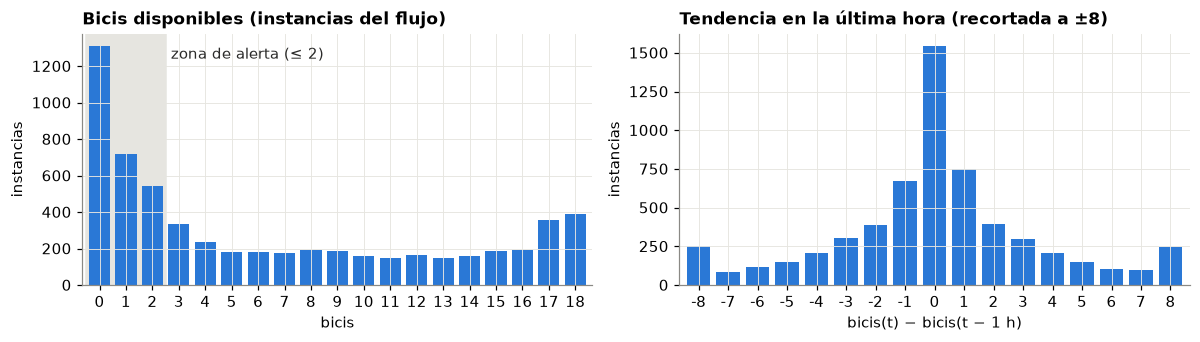

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
f["bicis"].astype(int).value_counts().sort_index().plot.bar(ax=axes[0], color=AZUL, width=0.8)
axes[0].axvspan(-0.5, UMBRAL_POCAS + 0.5, color=SOMBRA, zorder=0)
axes[0].set_title("Bicis disponibles (instancias del flujo)")
axes[0].set_xlabel("bicis"); axes[0].set_ylabel("instancias")
axes[0].text(UMBRAL_POCAS + 0.7, axes[0].get_ylim()[1] * 0.9, "zona de alerta (≤ 2)", color=TINTA)
axes[0].tick_params(axis="x", rotation=0)

f["tendencia_1h"].dropna().clip(-8, 8).astype(int).value_counts().sort_index().plot.bar(ax=axes[1], color=AZUL, width=0.8)
axes[1].set_title("Tendencia en la última hora (recortada a ±8)")
axes[1].set_xlabel("bicis(t) − bicis(t − 1 h)"); axes[1].set_ylabel("instancias")
axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

## 3.3 Patrones diarios y semanales: un *drift* recurrente y esperado

Si el uso de la estación depende de la hora y del tipo de día, la distribución de los datos **cambia varias veces al día y vuelve a cambiar el fin de semana**. Es un cambio previsible y recurrente: hay que tenerlo en cuenta para no confundirlo con un drift "de verdad".

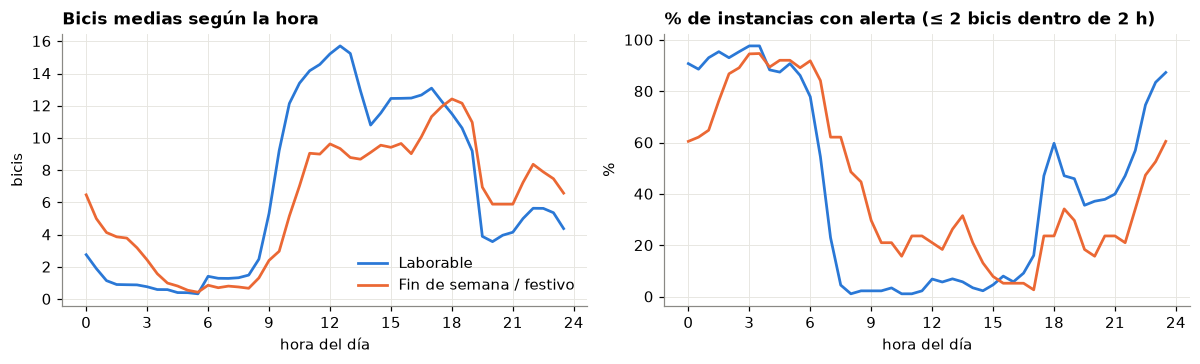

In [47]:
f["tipo_dia"] = np.where((f["es_finde"] == 1) | (f["es_festivo"] == 1), "Fin de semana / festivo", "Laborable")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), sharex=True)
for tipo, color in [("Laborable", AZUL), ("Fin de semana / festivo", NARANJA)]:
    g = f[f["tipo_dia"] == tipo].groupby("hora")
    axes[0].plot(g["bicis"].mean(), color=color, lw=1.8, label=tipo)
    axes[1].plot(100 * g["pocas_bicis_2h"].mean(), color=color, lw=1.8, label=tipo)
axes[0].set_title("Bicis medias según la hora"); axes[0].set_ylabel("bicis")
axes[1].set_title("% de instancias con alerta (≤ 2 bicis dentro de 2 h)"); axes[1].set_ylabel("%")
for ax in axes:
    ax.set_xlabel("hora del día"); ax.set_xticks(range(0, 25, 3))
axes[0].legend(frameon=False)
plt.tight_layout(); plt.show()

In [48]:
por_dia = f.groupby("dia_semana").agg(bicis_media=("bicis", "mean"), pct_alerta=("pocas_bicis_2h", "mean"))
por_dia.index = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
por_dia["pct_alerta"] *= 100
por_dia.round(1).T

,lun,mar,mié,jue,vie,sáb,dom
bicis_media,6.1,6.6,6.5,6.8,7.3,8.0,4.1
pct_alerta,45.3,44.1,44.4,44.9,35.9,34.3,52.1


## 3.4 Evolución a lo largo del periodo: ¿cambia el uso de la estación?

Medimos el **uso** de la estación como el número de bicis que entran o salen al día (la suma de `movimientos_30min`).

In [49]:
uso_diario = f["movimientos_30min"].resample("D").sum()
instancias_dia = f["bicis"].resample("D").count()
dias_completos = instancias_dia[instancias_dia >= 44].index      # al menos 44 de las 48 medias horas
print("Días incompletos que se descartan:", [d.strftime("%d-%m") for d in instancias_dia.index.difference(dias_completos)])
uso_diario = uso_diario[uso_diario.index.isin(dias_completos)]

diario = pd.DataFrame({
    "uso": uso_diario,
    "pct_alerta": 100 * f["pocas_bicis_2h"].resample("D").mean(),
    "bicis_media": f["bicis"].resample("D").mean(),
    "temperatura": f["temperatura"].resample("D").mean(),
}).dropna()
diario["laborable"] = (diario.index.dayofweek < 5) & ~diario.index.isin(FESTIVOS)
print(f"Días completos: {len(diario)}")

mensual = diario[diario["laborable"]].groupby(diario[diario["laborable"]].index.month).mean(numeric_only=True)
mensual.index = ["jun", "jul", "ago", "sep", "oct"][:len(mensual)]
print("Días LABORABLES, media por mes:")
mensual.drop(columns="laborable").round(1)

Días incompletos que se descartan: ['05-08', '15-09', '16-09', '05-10']
Días completos: 123
Días LABORABLES, media por mes:


,uso,pct_alerta,bicis_media,temperatura
jun,234.0,47.6,6.3,21.4
jul,221.6,40.2,7.1,23.0
ago,194.8,33.0,7.7,23.3
sep,232.2,49.6,5.7,21.9
oct,250.5,50.0,6.3,20.6


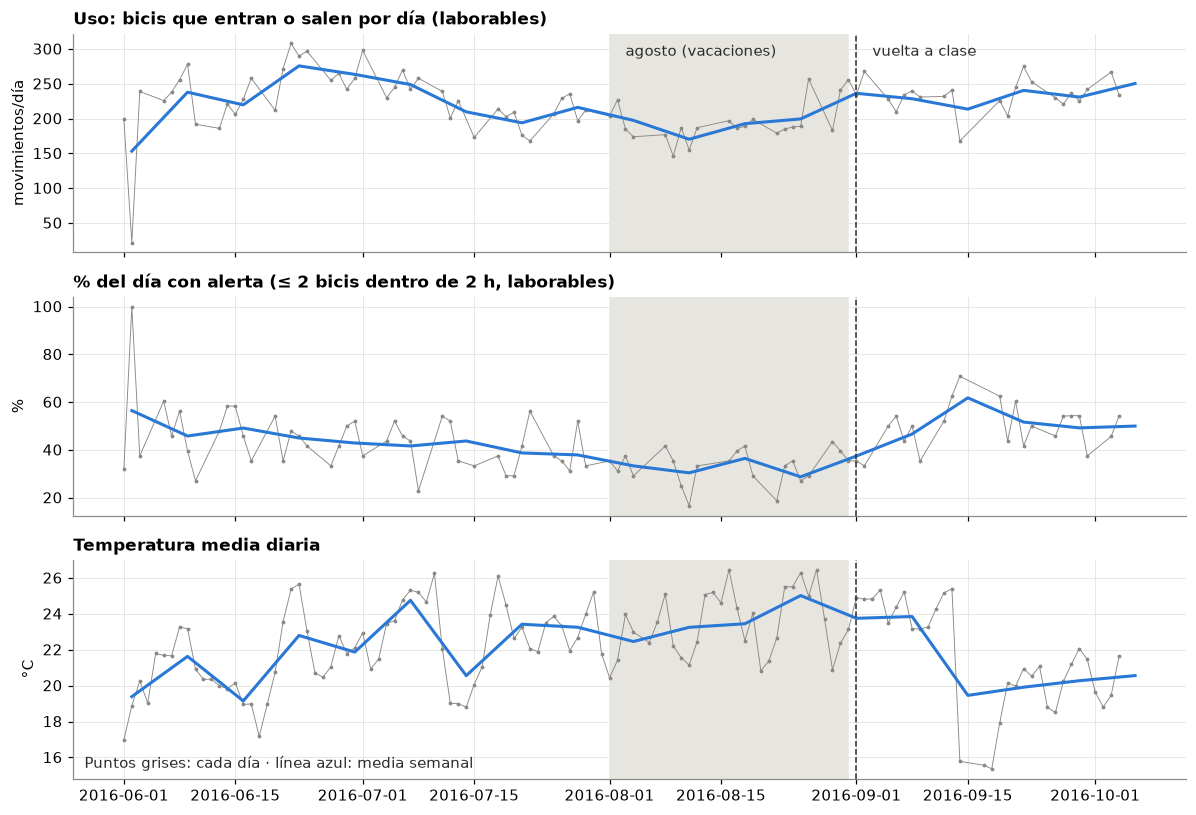

In [50]:
# Media semanal, dibujada en el centro de cada semana (lunes a domingo)
semanal = diario[diario["laborable"]].resample("W-SUN").mean(numeric_only=True)
semanal.index = semanal.index - pd.Timedelta(days=3)
paneles = [("uso", "Uso: bicis que entran o salen por día (laborables)", "movimientos/día"),
           ("pct_alerta", "% del día con alerta (≤ 2 bicis dentro de 2 h, laborables)", "%"),
           ("temperatura", "Temperatura media diaria", "°C")]

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, (col, titulo, unidad) in zip(axes, paneles):
    serie_d = diario[col] if col == "temperatura" else diario.loc[diario["laborable"], col]
    ax.plot(serie_d.index, serie_d, color=GRIS, lw=0.6, marker=".", ms=3)
    if col == "temperatura":
        serie_s = diario[col].resample("W-SUN").mean()
        serie_s.index = serie_s.index - pd.Timedelta(days=3)
    else:
        serie_s = semanal[col]
    ax.plot(serie_s.index, serie_s, color=AZUL, lw=2)
    ax.axvspan(pd.Timestamp("2016-08-01"), pd.Timestamp("2016-08-31"), color=SOMBRA, zorder=0)
    ax.axvline(pd.Timestamp("2016-09-01"), color=TINTA, ls="--", lw=1)
    ax.set_title(titulo); ax.set_ylabel(unidad)
axes[0].text(pd.Timestamp("2016-08-03"), axes[0].get_ylim()[1] * 0.95, "agosto (vacaciones)", va="top", color=TINTA)
axes[0].text(pd.Timestamp("2016-09-03"), axes[0].get_ylim()[1] * 0.95, "vuelta a clase", va="top", color=TINTA)
axes[2].text(0.01, 0.05, "Puntos grises: cada día · línea azul: media semanal", transform=axes[2].transAxes, color=TINTA)
plt.tight_layout(); plt.show()

## 3.5 Influencia del tiempo meteorológico

¿Se usan menos bicis cuando llueve? Comparamos el uso por media hora (movimientos de bicis en cada intervalo) con y sin lluvia, separando laborables y fines de semana y en horario diurno (8:00-21:00), para que la hora del día no enmascare el efecto.

In [51]:
m = f.rename(columns={"movimientos_30min": "movimientos"})
m = m[(m["hora"] >= 8) & (m["hora"] <= 21)]
tabla_lluvia = m.groupby(["tipo_dia", m["llueve"].map({0: "sin lluvia", 1: "con lluvia"})])["movimientos"].agg(["mean", "size"])
tabla_lluvia.columns = ["movimientos medios por 30 min", "instancias"]
print(f"Instancias con lluvia: {f['llueve'].mean():.1%} del flujo")
tabla_lluvia.round(2)

Instancias con lluvia: 11.6% del flujo


movimientos medios por 30 min  instancias
tipo_dia                llueve                                               
Fin de semana / festivo con lluvia                           4.11         126
                        sin lluvia                           4.92         896
Laborable               con lluvia                           5.93         239
                        sin lluvia                           7.20        2101

## 3.6 Autocorrelación

Los detectores de drift (KSWIN, ADWIN, DDM…) suponen observaciones **independientes**. Si una variable está muy autocorrelacionada o tiene un ciclo diario, un detector puede confundir el ciclo con un cambio.

In [52]:
retardos = {"30 min": 1, "1 h": 2, "6 h": 12, "12 h": 24, "1 día": 48, "1 semana": 336}
autocorr = pd.DataFrame({
    var: {nombre: f[var].asfreq(FREQ).autocorr(k) for nombre, k in retardos.items()}
    for var in ["bicis", "temperatura", "pocas_bicis_2h"]
}).round(2)
autocorr.index.name = "retardo"
autocorr

,bicis,temperatura,pocas_bicis_2h
retardo,,,
30 min,0.91,0.96,0.77
1 h,0.81,0.94,0.66
6 h,0.06,0.33,0.01
12 h,-0.39,-0.25,-0.34
1 día,0.55,0.78,0.47
1 semana,0.69,0.56,0.56


## 3.7 Resumen del exploratorio e hipótesis de drift

### ¿Está bien construido el flujo?

Sí, con matices que hay que tener en cuenta:
- **5.980 instancias, una cada 30 minutos**, del 1 de junio al 5 de octubre de 2016, en orden estricto y sin duplicados. La etiqueta coincide en el 100 % de los casos con las bicis de 2 horas después, así que **no hay fugas del futuro**.
- **27 saltos** en el flujo: los intervalos sin lecturas por cortes del recolector y las instancias que se quedan sin etiqueta porque no hay datos 2 horas después. El mayor es del 15 al 16 de septiembre (~27 h); los demás son de 30-60 minutos. No se rellenan: el flujo simplemente salta, igual que en un sistema real cuando se cae la fuente.
- **Clases equilibradas:** el 43 % de las instancias son alerta (2 bicis o menos dentro de 2 horas).
- **Anomalías:** el **2 de junio** la estación marca 0 bicis todo el día (probablemente fuera de servicio) y la **temperatura tiene 59 picos aislados** de más de 3 °C que vuelven al valor anterior en la siguiente media hora (errores de la fuente meteorológica). Hay que recordarlo al aplicar detectores sobre la temperatura: un detector sensible, como Page-Hinkley, puede reaccionar a estos picos.
- La estación tiene capacidad para unas **18 bicis**: además de vaciarse, a menudo se llena (17-18 bicis), lo que también limita su uso.

### Qué patrones tiene el flujo

- **Ciclo diario muy marcado (drift recurrente).** En laborables la estación está casi vacía de 0:00 a 8:00, se llena a partir de las 9:00 (hasta ~16 bicis de media a las 12:30) y se vacía otra vez a partir de las 19:00. Por eso las alertas (que miran 2 horas adelante) están por encima del 85 % de 23:00 a 6:00, casi desaparecen entre las 7:30 y las 17:00 y vuelven a partir de las 17:30. En fin de semana se llena más tarde y menos, y el **domingo** es el día con más alertas (52 %). La autocorrelación de las bicis es 0,55 a un día y 0,69 a una semana. **Un detector aplicado directamente sobre `bicis` detectaría este ciclo, no un cambio real.**
- **Cambio de uso en vacaciones y a la vuelta (laborables):**

| Mes | Movimientos/día | % del día con alerta | Bicis medias |
|---|---|---|---|
| Junio | 234 | 48 % | 6,3 |
| Julio | 222 | 40 % | 7,1 |
| Agosto | 195 (−17 % frente a junio) | 33 % | 7,7 |
| Septiembre | 232 | 50 % | 5,7 |

En agosto se usa menos la estación y **se queda menos veces sin bicis**; en septiembre el uso vuelve al nivel de junio y las alertas suben del 33 % al 50 %. (Octubre solo tiene 3 días laborables completos y no se usa para conclusiones.)
- **El tiempo influye, pero menos:** con lluvia hay un 18 % menos de movimientos en laborables y un 16 % menos en fin de semana. A mediados de septiembre la temperatura baja ~5 °C de golpe, justo cuando suben las alertas: habrá que separar ambos efectos.

### Hipótesis de drift que vamos a comprobar

| | Hipótesis | Señal que se vigila | Métodos | Para qué |
|---|---|---|---|---|
| **H1** | ***Data drift*** **en el uso** al empezar agosto (vacaciones) y al volver en septiembre | uso y nivel de bicis, quitando antes el ciclo diario y semanal | ADWIN, KSWIN, Page-Hinkley | Avisar de un cambio de comportamiento **sin esperar a las etiquetas** |
| **H2** | ***Concept drift*** **en septiembre**: a la misma hora y el mismo día, cambia la probabilidad de quedarse sin bicis | error del modelo (acierto/fallo) | DDM, EDDM, HDDM_A, HDDM_W, Page-Hinkley, ADWIN | Saber **cuándo el modelo de alerta deja de ser fiable** y hay que adaptarlo |
| **H3** | El **ciclo diario y semanal** es un drift recurrente y esperado: no debería disparar alarmas | `bicis` tal cual frente a desestacionalizada | ADWIN, KSWIN, Page-Hinkley | Justificar que hay que quitar la estacionalidad antes de vigilar una variable |
| **H4** | La **bajada de temperatura** de mediados de septiembre es *data drift* en la meteorología, que no tiene por qué afectar al modelo | temperatura (media diaria, para evitar los picos) | ADWIN, KSWIN | Contrastar *data drift* y *concept drift*: un cambio en los datos no siempre obliga a reentrenar |

### Implicaciones para la modelización (siguiente notebook)

- El estado actual (`bicis`, `tendencia_1h`) y el calendario (`hora`, `dia_semana`) son las variables clave. **Hay que comparar siempre con el *baseline* de persistencia** ("si ahora hay 2 o menos, dentro de 2 horas también"): la autocorrelación de las bicis es alta (0,81 a 1 hora), así que no será fácil de batir.
- La evaluación será **prequential** (predecir, evaluar y después aprender) sobre este flujo, sin usar nunca información futura y **teniendo en cuenta que la etiqueta llega 2 horas tarde**.